<a href="https://colab.research.google.com/github/KaviduIsura/EuroSAT-Land-Use-Classification/blob/main/eurosat-cw1/notebooks/06_cnn_pytorch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 06 - Neural Model 2: Small CNN (PyTorch)

Three-block convolutional neural network. Learns spatial features (edges → textures → structures) hierarchically from raw pixels.

**Architecture:** 3× [Conv3×3 → BatchNorm → ReLU → MaxPool] → AdaptiveAvgPool → Dropout → Linear(10)

> The CNN has ~100K params vs MLP's ~6.4M, yet achieves better performance because convolutions exploit spatial structure that flattening destroys.


## Setup

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import numpy as np
import matplotlib.pyplot as plt
import json, os, time
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, classification_report
from google.colab import drive

drive.mount('/content/drive')

# Restore splits and preprocessing from Drive if not found locally
os.makedirs('splits', exist_ok=True)
os.makedirs('figures', exist_ok=True)
os.makedirs('metrics', exist_ok=True)
os.makedirs('checkpoints', exist_ok=True)

if not os.path.exists('splits/split_indices.npz'):
    print('Syncing splits from Google Drive...')
    !cp -r /content/drive/MyDrive/ann_cw1/splits/* splits/

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {DEVICE}')

data   = np.load('/content/drive/MyDrive/ann_cw1/eurosat_64.npz')
X, y   = data['X'], data['y']
splits = np.load('splits/split_indices.npz')
train_idx, val_idx, test_idx = splits['train'], splits['val'], splits['test']

with open('splits/preprocessing.json') as f:
    prep = json.load(f)
MEAN    = prep['mean']
STD     = prep['std']
CLASSES = prep['classes']
print(f'Loaded. Device={DEVICE}, classes={len(CLASSES)}')

Mounted at /content/drive
Syncing splits from Google Drive...
Using device: cuda
Loaded. Device=cuda, classes=10


## Dataset & DataLoaders (same as MLP notebook)

In [2]:
class EuroSATDataset(torch.utils.data.Dataset):
    def __init__(self, X, y, indices, transform=None):
        self.X = X[indices]; self.y = y[indices]; self.transform = transform

    def __len__(self): return len(self.y)

    def __getitem__(self, i):
        img = torch.tensor(self.X[i], dtype=torch.float32) / 255.0
        img = (img - torch.tensor(MEAN)) / torch.tensor(STD)
        img = img.permute(2, 0, 1)
        if self.transform:
            img = self.transform(img)
        return img, int(self.y[i])

train_tf = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomApply([transforms.RandomRotation((90, 90))], p=0.5),
])

BATCH = 64
train_loader = DataLoader(EuroSATDataset(X, y, train_idx, transform=train_tf), batch_size=BATCH, shuffle=True,  num_workers=2)
val_loader   = DataLoader(EuroSATDataset(X, y, val_idx),   batch_size=BATCH, shuffle=False, num_workers=2)
test_loader  = DataLoader(EuroSATDataset(X, y, test_idx),  batch_size=BATCH, shuffle=False, num_workers=2)
print('DataLoaders ready.')

DataLoaders ready.


## CNN Architecture

| Layer | Output Shape | Activation | Params |
|-------|-------------|-----------|--------|
| Input | (B, 3, 64, 64) | — | 0 |
| Conv3×3(3→32) + BN | (B, 32, 64, 64) | ReLU | 896 |
| MaxPool2d | (B, 32, 32, 32) | — | 0 |
| Conv3×3(32→64) + BN | (B, 64, 32, 32) | ReLU | 18,560 |
| MaxPool2d | (B, 64, 16, 16) | — | 0 |
| Conv3×3(64→128) + BN | (B, 128, 16, 16) | ReLU | 73,984 |
| MaxPool2d | (B, 128, 8, 8) | — | 0 |
| AdaptiveAvgPool(1) | (B, 128, 1, 1) | — | 0 |
| Flatten | (B, 128) | — | 0 |
| Dropout(0.3) | (B, 128) | — | 0 |
| Linear(128→10) | (B, 10) | — (logits) | 1,290 |
| **Total** | | | **~94,730** |

In [3]:
def conv_block(in_ch, out_ch):
    """Conv3x3 + BatchNorm + ReLU + MaxPool2d"""
    return nn.Sequential(
        nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(2)
    )

def make_cnn(dropout=0.3):
    return nn.Sequential(
        conv_block(3, 32),     # 64x64 -> 32x32
        conv_block(32, 64),    # 32x32 -> 16x16
        conv_block(64, 128),   # 16x16 -> 8x8
        nn.AdaptiveAvgPool2d(1),  # 8x8 -> 1x1 (global average pool)
        nn.Flatten(),
        nn.Dropout(dropout),
        nn.Linear(128, 10)
    )

cnn = make_cnn().to(DEVICE)
params = sum(p.numel() for p in cnn.parameters() if p.requires_grad)
print(f'CNN trainable parameters: {params:,}')
print(cnn)

# Shape sanity check
dummy = torch.zeros(2, 3, 64, 64).to(DEVICE)
out   = cnn(dummy)
print(f'\nOutput shape for batch of 2: {out.shape}  (expected: torch.Size([2, 10]))')

CNN trainable parameters: 94,986
Sequential(
  (0): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (1): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (2): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (3): AdaptiveAvgPool2d

## Training - 3 Seeds (T4a)

**Design choices:**
- **Loss:** CrossEntropyLoss - softmax is inside; output logits.
- **Activation:** ReLU - avoids saturating gradients; BatchNorm stabilises training.
- **Optimiser:** Adam + weight_decay (AdamW-style).
- **Depth:** 3 conv blocks - shallow layers learn edges, deeper layers learn textures/shapes.
- **Regularisation:** BatchNorm, Dropout, weight decay, augmentation, early stopping.

In [4]:
def train_epoch(model, loader, criterion, optimizer):
    model.train()
    total = 0
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad()
        loss = criterion(model(xb), yb)
        loss.backward()
        optimizer.step()
        total += loss.item() * len(yb)
    return total / len(loader.dataset)

def evaluate_loss(model, loader, criterion):
    model.eval(); total = 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            total += criterion(model(xb), yb).item() * len(yb)
    return total / len(loader.dataset)

def evaluate_metrics(model, loader):
    model.eval(); preds, trues = [], []
    with torch.no_grad():
        for xb, yb in loader:
            preds.extend(model(xb.to(DEVICE)).argmax(1).cpu().numpy())
            trues.extend(yb.numpy())
    return np.array(trues), np.array(preds)

print('Training helpers defined.')

Training helpers defined.


In [5]:
CONFIG = dict(lr=1e-3, weight_decay=1e-4, dropout=0.3,
              batch_size=64, max_epochs=40, patience=5)

SEEDS = [0, 1, 2]
cnn_results = []
train_loss_all, val_loss_all = [], []

for seed in SEEDS:
    print(f'\n--- CNN Seed {seed} ---')
    torch.manual_seed(seed); np.random.seed(seed)

    model     = make_cnn(dropout=CONFIG['dropout']).to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=CONFIG['lr'],
                           weight_decay=CONFIG['weight_decay'])
    ckpt_path = f'checkpoints/cnn_seed{seed}.pt'

    best_val_loss, wait = float('inf'), 0
    tr_curve, va_curve = [], []

    for epoch in range(CONFIG['max_epochs']):
        tl = train_epoch(model, train_loader, criterion, optimizer)
        vl = evaluate_loss(model, val_loader, criterion)
        tr_curve.append(tl); va_curve.append(vl)
        print(f'  Epoch {epoch+1:02d}: train={tl:.4f}  val={vl:.4f}')
        if vl < best_val_loss:
            best_val_loss, wait = vl, 0
            torch.save(model.state_dict(), ckpt_path)
            !cp {ckpt_path} /content/drive/MyDrive/ann_cw1/checkpoints/ 2>/dev/null || true
        else:
            wait += 1
            if wait >= CONFIG['patience']:
                print(f'  Early stopping at epoch {epoch+1}')
                break

    train_loss_all.append(tr_curve)
    val_loss_all.append(va_curve)

    model.load_state_dict(torch.load(ckpt_path))
    y_true_val, y_pred_val = evaluate_metrics(model, val_loader)
    y_true_te,  y_pred_te  = evaluate_metrics(model, test_loader)
    val_f1  = f1_score(y_true_val, y_pred_val, average='macro')
    test_f1 = f1_score(y_true_te,  y_pred_te,  average='macro')
    val_acc = accuracy_score(y_true_val, y_pred_val)

    cnn_results.append({'seed': seed, 'val_macro_f1': val_f1,
                        'test_macro_f1': test_f1, 'val_accuracy': val_acc})
    print(f'  Val F1={val_f1:.4f}  Test F1={test_f1:.4f}')


--- CNN Seed 0 ---
  Epoch 01: train=0.9879  val=0.7150
  Epoch 02: train=0.6900  val=0.6585
  Epoch 03: train=0.6023  val=0.5515
  Epoch 04: train=0.5423  val=0.5658
  Epoch 05: train=0.4961  val=0.4260
  Epoch 06: train=0.4611  val=0.7313
  Epoch 07: train=0.4372  val=0.4736
  Epoch 08: train=0.4107  val=0.4297
  Epoch 09: train=0.3857  val=0.3736
  Epoch 10: train=0.3668  val=0.3539
  Epoch 11: train=0.3607  val=0.3149
  Epoch 12: train=0.3422  val=0.3606
  Epoch 13: train=0.3390  val=0.4762
  Epoch 14: train=0.3227  val=0.3222
  Epoch 15: train=0.3135  val=0.2703
  Epoch 16: train=0.3055  val=0.3066
  Epoch 17: train=0.3053  val=0.3773
  Epoch 18: train=0.2930  val=0.2704
  Epoch 19: train=0.2880  val=0.2428
  Epoch 20: train=0.2811  val=0.2204
  Epoch 21: train=0.2764  val=0.2458
  Epoch 22: train=0.2702  val=0.2418
  Epoch 23: train=0.2666  val=0.2051
  Epoch 24: train=0.2621  val=0.3134
  Epoch 25: train=0.2512  val=0.2364
  Epoch 26: train=0.2576  val=0.2364
  Epoch 27: train=

## Results Summary

In [6]:
val_f1s  = [r['val_macro_f1'] for r in cnn_results]
test_f1s = [r['test_macro_f1'] for r in cnn_results]

print('CNN Results (3 seeds)')
print(f'{"Seed":>5}  {"Val F1":>10}  {"Test F1":>10}')
for r in cnn_results:
    print(f'{r["seed"]:>5}  {r["val_macro_f1"]:>10.4f}  {r["test_macro_f1"]:>10.4f}')
print(f'  Mean  {np.mean(val_f1s):>10.4f}  {np.mean(test_f1s):>10.4f}')
print(f'  Std   {np.std(val_f1s):>10.4f}  {np.std(test_f1s):>10.4f}')

summary = {
    'model': 'cnn_pytorch', 'config': CONFIG,
    'seeds': cnn_results,
    'val_mean': round(np.mean(val_f1s), 4), 'val_std': round(np.std(val_f1s), 4),
    'test_mean': round(np.mean(test_f1s), 4), 'test_std': round(np.std(test_f1s), 4)
}
with open('metrics/cnn_results.json', 'w') as f:
    json.dump(summary, f, indent=2)
!cp metrics/cnn_results.json /content/drive/MyDrive/ann_cw1/metrics/ 2>/dev/null || true
print('Saved: metrics/cnn_results.json (backed up to Drive)')

CNN Results (3 seeds)
 Seed      Val F1     Test F1
    0      0.9262      0.9263
    1      0.9040      0.9100
    2      0.8902      0.8946
  Mean      0.9068      0.9103
  Std       0.0148      0.0129
Saved: metrics/cnn_results.json (backed up to Drive)


## Loss Curves

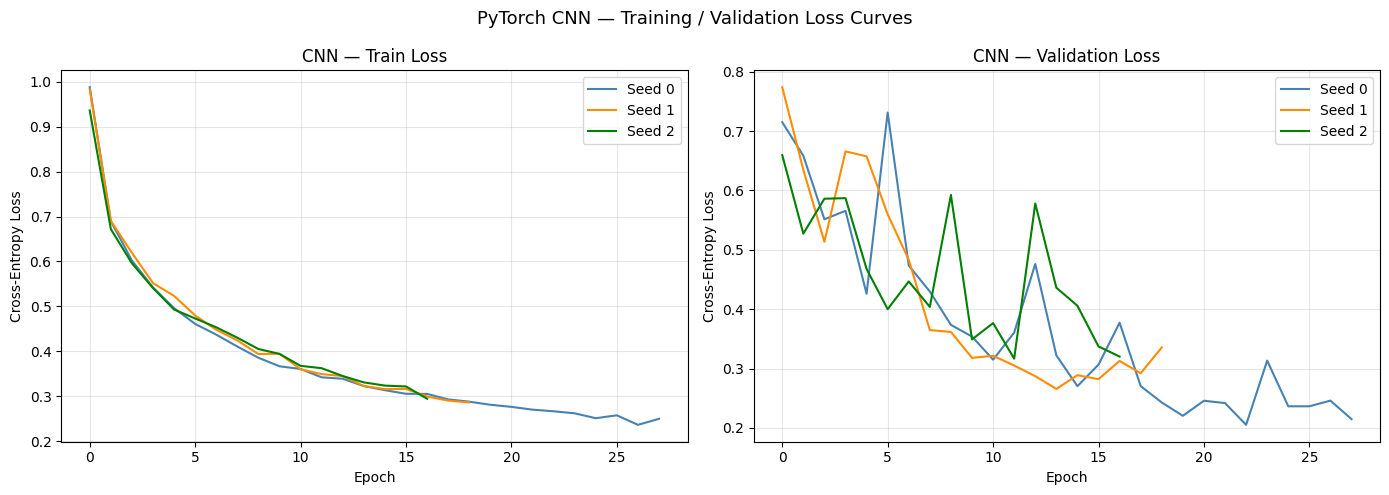

Saved: figures/cnn_loss_curves.png (backed up to Drive)


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = ['steelblue', 'darkorange', 'green']
for s, (tl, vl) in enumerate(zip(train_loss_all, val_loss_all)):
    axes[0].plot(tl, color=colors[s], label=f'Seed {s}')
    axes[1].plot(vl, color=colors[s], label=f'Seed {s}')
for ax, title in zip(axes, ['Train Loss', 'Validation Loss']):
    ax.set_xlabel('Epoch'); ax.set_ylabel('Cross-Entropy Loss')
    ax.set_title(f'CNN — {title}'); ax.legend(); ax.grid(True, alpha=0.3)
plt.suptitle('PyTorch CNN — Training / Validation Loss Curves', fontsize=13)
plt.tight_layout()
plt.savefig('figures/cnn_loss_curves.png', dpi=150)
!cp figures/cnn_loss_curves.png /content/drive/MyDrive/ann_cw1/figures/ 2>/dev/null || true
plt.show()
print('Saved: figures/cnn_loss_curves.png (backed up to Drive)')

## Confusion Matrix (Test Set)

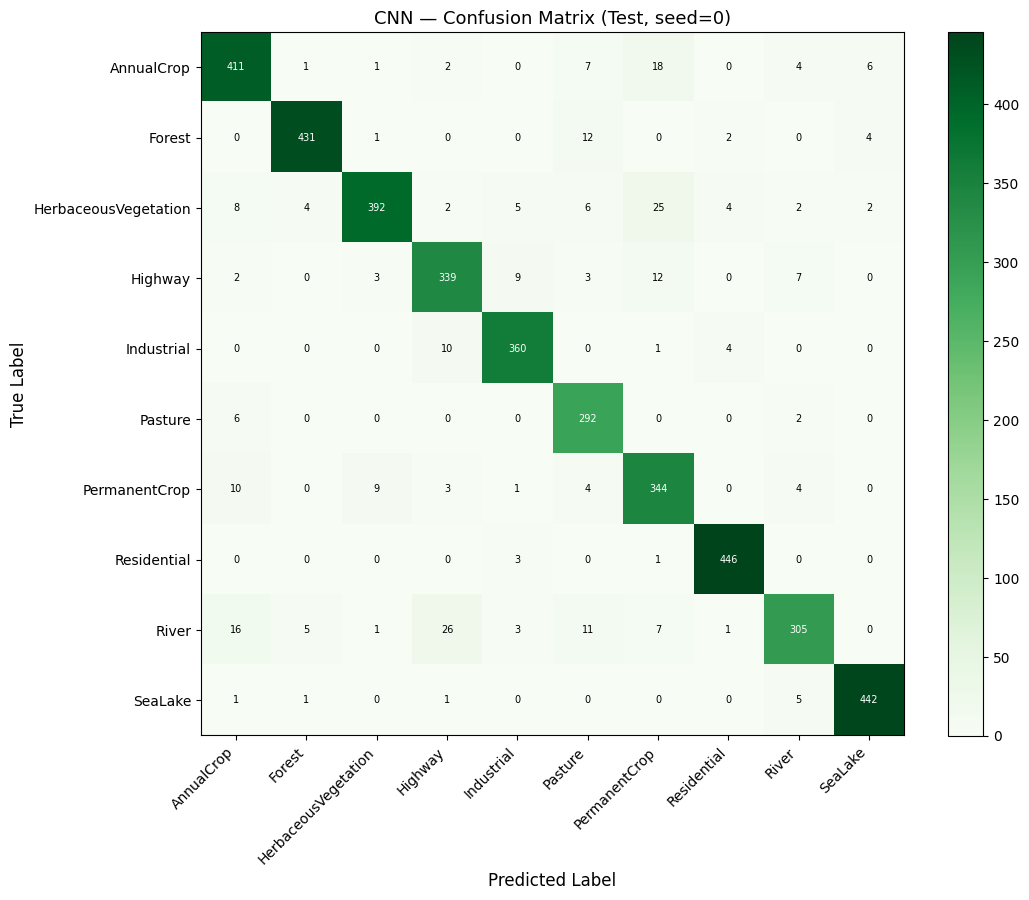

Saved: figures/confusion_cnn_test.png (backed up to Drive)


In [8]:
best_seed  = max(cnn_results, key=lambda r: r['val_macro_f1'])['seed']
best_model = make_cnn().to(DEVICE)
best_model.load_state_dict(torch.load(f'checkpoints/cnn_seed{best_seed}.pt'))
y_true, y_pred = evaluate_metrics(best_model, test_loader)

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(cm, cmap='Greens')
plt.colorbar(im, ax=ax)
ax.set_xticks(range(10)); ax.set_xticklabels(CLASSES, rotation=45, ha='right')
ax.set_yticks(range(10)); ax.set_yticklabels(CLASSES)
ax.set_xlabel('Predicted Label', fontsize=12); ax.set_ylabel('True Label', fontsize=12)
ax.set_title(f'CNN — Confusion Matrix (Test, seed={best_seed})', fontsize=13)
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i,j], ha='center', va='center', fontsize=7,
                color='white' if cm[i,j] > cm.max()/2 else 'black')
plt.tight_layout()
plt.savefig('figures/confusion_cnn_test.png', dpi=150)
!cp figures/confusion_cnn_test.png /content/drive/MyDrive/ann_cw1/figures/ 2>/dev/null || true
plt.show()
print('Saved: figures/confusion_cnn_test.png (backed up to Drive)')

## T4c Ablation - Remove Dropout from CNN

In [9]:
print('--- Ablation: CNN without Dropout ---')
ablation_results = []

for seed in SEEDS:
    torch.manual_seed(seed); np.random.seed(seed)
    model = make_cnn(dropout=0.0).to(DEVICE)   # Only change: dropout=0
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=CONFIG['lr'],
                           weight_decay=CONFIG['weight_decay'])
    ckpt_path = f'checkpoints/cnn_ablation_seed{seed}.pt'
    best_val_loss, wait = float('inf'), 0

    for epoch in range(CONFIG['max_epochs']):
        train_epoch(model, train_loader, criterion, optimizer)
        vl = evaluate_loss(model, val_loader, criterion)
        if vl < best_val_loss:
            best_val_loss, wait = vl, 0
            torch.save(model.state_dict(), ckpt_path)
            !cp {ckpt_path} /content/drive/MyDrive/ann_cw1/checkpoints/ 2>/dev/null || true
        else:
            wait += 1
            if wait >= CONFIG['patience']:
                break

    model.load_state_dict(torch.load(ckpt_path))
    y_true_val, y_pred_val = evaluate_metrics(model, val_loader)
    val_f1 = f1_score(y_true_val, y_pred_val, average='macro')
    ablation_results.append({'seed': seed, 'val_macro_f1': val_f1})
    print(f'  Seed {seed}: val F1={val_f1:.4f}')

abl_f1s = [r['val_macro_f1'] for r in ablation_results]
print(f'Ablation  mean={np.mean(abl_f1s):.4f}  std={np.std(abl_f1s):.4f}')
print(f'Full CNN  mean={np.mean(val_f1s):.4f}  std={np.std(val_f1s):.4f}')
print(f'Effect of removing dropout: Δ = {np.mean(abl_f1s)-np.mean(val_f1s):+.4f}')

abl_summary = {
    'model': 'cnn_no_dropout', 'change': 'dropout=0.0',
    'seeds': ablation_results,
    'val_mean': round(np.mean(abl_f1s), 4), 'val_std': round(np.std(abl_f1s), 4)
}
with open('metrics/cnn_ablation.json', 'w') as f:
    json.dump(abl_summary, f, indent=2)
!cp metrics/cnn_ablation.json /content/drive/MyDrive/ann_cw1/metrics/ 2>/dev/null || true
print('Saved: metrics/cnn_ablation.json (backed up to Drive)')

--- Ablation: CNN without Dropout ---
  Seed 0: val F1=0.9234
  Seed 1: val F1=0.9156
  Seed 2: val F1=0.9034
Ablation  mean=0.9141  std=0.0082
Full CNN  mean=0.9068  std=0.0148
Effect of removing dropout: Δ = +0.0073
Saved: metrics/cnn_ablation.json (backed up to Drive)
